# CohortX Task 3 — Joint review (descriptive audit) of the reference solution
**Purpose.** Two reviewers (Altammami and Ares-Rufo), meeting and reviewing together, were given `solution.csv` (23 conditions × three roles: KEEP / ASSOCIATION / DIFF) and the MIMIC-IV ICD-10 dictionary and asked whether codes should be **added, moved or removed**. They returned `solution_revised.csv` and a decision log (`changes_reasons.csv`). This notebook

1. checks the integrity of the three files and reconciles the log with the two solutions,
2. quantifies how much of the original solution survived review, by role, condition and split,
3. characterises *why* codes were changed (themes, concentration in a few large blocks),
4. measures original-vs-revised agreement (set F1, Cohen's κ, category level) and
5. gives an evaluation of the original solution, with caveats about what this review can and cannot show.

**Important caveat (read first).** The reviewers *edited the original solution*; this was not a blind, independent re-annotation. Agreement statistics here are therefore **optimistic** (anchoring) and must not be reported as inter-rater reliability. The review is reported as a **descriptive audit of the reference**. Timing (stated by the authors): initial coding by Alzahrani and Turki in January 2026, about 20 hours of work; revision by Altammami and Ares-Rufo in November 2026, over 8 days.

Requirements: `pandas`, `numpy`, `matplotlib`, `openpyxl`.

## Summary of findings
*(Figures below are produced by the cells that follow; they were checked against the notebook output.)*

**Data integrity.** The three files are consistent: all codes exist in the dictionary, no code is assigned to two roles within a condition, and the 3,017 code changes derived from comparing the two solutions match the 3,017 non-housekeeping rows of the log one-to-one. The original `solution.csv` contained 11 duplicated codes in one cell (Latent Adrenal Insufficiency, KEEP); the reviewer cleaned them up.

**Overall verdict on the original solution.** KEEP was largely sound, ASSOCIATION was moderately sound and DIFF was weak.

| | KEEP | ASSOCIATION | DIFF |
|---|---|---|---|
| Original codes → revised codes | 2,018 → 2,035 | 1,327 → 1,591 | 1,495 → 1,117 |
| Confirmed unchanged and unflagged | 60.2 % | 48.7 % | 23.3 % |
| Kept but flagged as debatable | 13.5 % | 28.0 % | 15.3 % |
| Moved to another role | 18.4 % | 2.3 % | 0.2 % |
| Removed | 7.9 % | 21.0 % | 61.3 % |
| Codes added by reviewer (share of revised) | 26.3 % | 25.1 % | 28.8 % |
| Macro F1, original vs revised (all 23) | 0.725 | 0.615 | 0.293 |
| Macro F1 (private / public) | 0.795 / 0.528 | 0.686 / 0.414 | 0.302 / 0.265 |

1. **DIFF is the main weakness.** All 916 removed DIFF codes come from just three conditions (Pneumonia 583, Hyperthyroidism 203, Enlarged Mediastinum 130), each a single "off-topic block" with **zero overlap** with the reviewer's DIFF for that condition.
2. **The change is concentrated.** 76 % of all removals are "off-topic" blocks; the 3 largest decisions account for 39 % and the 10 largest for 60 % of all changed codes. Pneumonia, Gout and Enlarged Mediastinum carry 60 % of changes.
3. **Missing content.** The reviewer added 1,257 codes that were in no role originally (about a quarter of each revised role). One decision alone adds 404 chronic-gout (M1A) codes to Gout KEEP.
4. **Role boundaries.** 372 original KEEP codes were moved to a secondary role (174 to ASSOCIATION, 198 to DIFF), mostly "differential, not the condition itself" (e.g. other crystal arthropathies for gout) or "cause/risk lesion" decisions.
5. **Empty roles were not accepted as genuine.** The original had 3 empty ASSOCIATION and 10 empty DIFF cells; the reviewer filled **all 13** (127 codes), so the revised reference has no empty cells.
6. **The public split changed far more than the private split** (new codes = 65 % vs 14 % of original codes; macro-F1 0.40 vs 0.59). Public conditions are those teams could tune on.
7. **Granularity.** 84-99 % of original selected 3-character families were selected in full; only 49-61 % are in the revised solution, i.e. the original was coarser (whole categories) than the reviewer's code-level choices.
8. **Residual uncertainty.** 871 codes (13 % of revised KEEP, 23 % ASSOCIATION, 20 % DIFF) were kept but flagged; this is where a further reviewer is most likely to disagree.

**How to read these numbers.** One reviewer, shown the original solution (non-blind), decided mostly at block level (139 distinct blocks for 3,017 changes). The figures are therefore an optimistic estimate of reference quality, not inter-rater reliability. Reviewer qualifications are not in the data supplied. Recommendations are in the last section.

In [1]:
import re, collections
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_rows', 200); pd.options.display.float_format = '{:,.3f}'.format
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

ROLES = ['KEEP', 'ASSOCIATION', 'DIFF']
ROLE_COL = {'KEEP': '#2a7f62', 'ASSOCIATION': '#c98a1b', 'DIFF': '#b04a4a'}

# Where the input files live (first folder that contains them wins)
for d in [Path('.'), Path('/mnt/user-data/uploads')]:
    if (d / 'solution.csv').exists():
        DATA_DIR = d; break
else:
    raise FileNotFoundError('Put solution.csv, solution_revised.csv, changes_reasons.csv and mimic-iv_icd-10_dict.xlsx next to the notebook.')
OUT_DIR = Path('analysis_outputs'); OUT_DIR.mkdir(exist_ok=True)
print('Reading from', DATA_DIR.resolve(), '| writing tables to', OUT_DIR.resolve())

Reading from /content | writing tables to /content/analysis_outputs


## 1. Load data and check integrity

In [2]:
orig = pd.read_csv(DATA_DIR/'solution.csv', keep_default_na=False)
rev  = pd.read_csv(DATA_DIR/'solution_revised.csv', keep_default_na=False)
log  = pd.read_csv(DATA_DIR/'changes_reasons.csv', keep_default_na=False)
dic  = pd.read_excel(DATA_DIR/'mimic-iv_icd-10_dict.xlsx', dtype=str)
DICT = dict(zip(dic.icd_code, dic.long_title))
CONDS = list(orig.Condition)
SPLIT = dict(zip(orig.Condition, orig.Usage))

EMPTY_TOKENS = {'', 'not applicable', 'n/a', 'na', 'none', 'nan'}   # placeholders that mean "empty set"
def parse(cell):
    items = [x.strip() for x in str(cell).split(';') if x.strip()]
    return [x for x in items if x.lower() not in EMPTY_TOKENS]

def to_sets(df):
    return {(r.Condition, k): set(parse(r[k])) for _, r in df.iterrows() for k in ROLES}
O, R = to_sets(orig), to_sets(rev)

def dup_count(df):
    return sum(len(parse(r[k])) - len(set(parse(r[k]))) for _, r in df.iterrows() for k in ROLES)
def cross_role(df):
    n = 0
    for _, r in df.iterrows():
        c = collections.Counter(x for k in ROLES for x in set(parse(r[k]))); n += sum(v > 1 for v in c.values())
    return n

checks = pd.DataFrame({
  'check': ['Conditions in each solution', 'Same conditions, same order', 'Same Public/Private usage',
            'Codes not in dictionary', 'Duplicate codes inside one cell (raw lists)',
            'Codes assigned to >1 role within a condition', 'Log codes not in dictionary',
            'Log description differs from dictionary title', 'Log rows (all actions)'],
  'original': [len(orig), '', '', sum(len(v - set(DICT)) for v in O.values()), dup_count(orig), cross_role(orig), '', '', ''],
  'revised':  [len(rev), '', '', sum(len(v - set(DICT)) for v in R.values()), dup_count(rev),  cross_role(rev), '', '', ''],
})
checks.loc[1, ['original','revised']] = [bool((orig.Condition == rev.Condition).all())] * 2
checks.loc[2, ['original','revised']] = [bool((orig.Usage == rev.Usage).all())] * 2
checks.loc[6, 'original'] = int((~log.Code.isin(DICT)).sum())
checks.loc[7, 'original'] = int((log.Code.map(DICT) != log.Description).sum())
checks.loc[8, 'original'] = len(log)
display(checks)
print('Split:', pd.Series(SPLIT).value_counts().to_dict(), '| dictionary size:', len(DICT))

,check,original,revised
0,Conditions in each solution,23,23
1,"Same conditions, same order",True,True
2,Same Public/Private usage,True,True
3,Codes not in dictionary,0,0
4,Duplicate codes inside one cell (raw lists),11,0
5,Codes assigned to >1 role within a condition,0,0
6,Log codes not in dictionary,0,
7,Log description differs from dictionary title,0,
8,Log rows (all actions),3899,


Split: {'Private': 17, 'Public': 6} | dictionary size: 97441


## 2. Reconcile the decision log with the two solution files
Every (condition, code) pair is given a **status derived directly from the two files** (unchanged / moved / removed / added) and then compared with the reviewer's log. The log also contains **`flagged`** rows: codes the reviewer *kept in the same role* but considered debatable (they are not changes).

In [3]:
rows = []
for cond in CONDS:
    o_role = {c: k for k in ROLES for c in O[(cond, k)]}
    r_role = {c: k for k in ROLES for c in R[(cond, k)]}
    for code_ in set(o_role) | set(r_role):
        o, r = o_role.get(code_), r_role.get(code_)
        status = ('added' if o is None else 'removed' if r is None else 'unchanged' if o == r else 'moved')
        rows.append((cond, code_, o, r, status))
chg = pd.DataFrame(rows, columns=['Condition','Code','Orig_Role','Rev_Role','Status'])
chg['Split'] = chg.Condition.map(SPLIT)
chg['Title'] = chg.Code.map(DICT)

# log: separate real changes from "flagged" (kept-but-doubtful) rows
flag = log[log.Action == 'flagged']
real = log[log.Action != 'flagged']
dup_rows = real[real.Reason.str.contains('duplicate entry')]            # housekeeping rows
real_core = real.drop(dup_rows.index)

flagged_keys = set(zip(flag.Condition, flag.Code))
chg['Flagged'] = [(c, k) in flagged_keys for c, k in zip(chg.Condition, chg.Code)]
reason_real = real_core.drop_duplicates(['Condition','Code']).set_index(['Condition','Code']).Reason
reason_flag = flag.drop_duplicates(['Condition','Code']).set_index(['Condition','Code']).Reason
idx = pd.MultiIndex.from_frame(chg[['Condition','Code']])
chg['Reason'] = reason_real.reindex(idx).values
chg['Reason'] = chg.Reason.fillna(pd.Series(reason_flag.reindex(idx).values, index=chg.index))
chg['Reason'] = chg.Reason.fillna('')

# 2a. does the log agree with the file-derived status?
m = real_core.merge(chg[['Condition','Code','Status','Orig_Role','Rev_Role']], on=['Condition','Code'], how='outer', indicator=True)
log_status = m.Action
agree = (m._merge == 'both') & (m.Action == m.Status)
print('Real changes derived from the files :', int((chg.Status != 'unchanged').sum()))
print('Real change rows in the log         :', len(real_core), f'(+ {len(dup_rows)} duplicate-cleanup rows, + {len(flag)} flagged rows)')
print('Log rows whose action matches files :', int(agree.sum()))
print('Derived changes missing from the log:', int(((m._merge == 'right_only') & (m.Status != 'unchanged')).sum()))
print('Log rows with no matching change    :', int(((m._merge == 'left_only')).sum()))
bad = m[~agree & ~((m._merge == 'right_only') & (m.Status == 'unchanged'))]
display(bad[['Condition','Code','Action','Status','Orig_Role','Rev_Role','Original_Class','Revised_Class']].head(20))

# 2b. flagged rows should be unchanged in the files
fl = chg[chg.Flagged]
print('Flagged codes that are unchanged in the files:', int((fl.Status == 'unchanged').sum()), 'of', len(fl))
print('Duplicate cleanup rows (code listed twice in an ORIGINAL cell):')
display(dup_rows.groupby('Condition').size().rename('duplicate rows'))

Real changes derived from the files : 3017
Real change rows in the log         : 3017 (+ 11 duplicate-cleanup rows, + 871 flagged rows)
Log rows whose action matches files : 3017
Derived changes missing from the log: 0
Log rows with no matching change    : 0


,Condition,Code,Action,Status,Orig_Role,Rev_Role,Original_Class,Revised_Class


Flagged codes that are unchanged in the files: 871 of 871
Duplicate cleanup rows (code listed twice in an ORIGINAL cell):


,duplicate rows
Condition,
Latent Adrenal Insufficiency,11


## 3. How much of the original solution survived review?
Fate of every **original** code, by role. "Confirmed" = unchanged and not flagged; "Kept, flagged" = unchanged but the reviewer marked it debatable.

Fate,Confirmed,"Kept, flagged",Moved to KEEP,Moved to ASSOCIATION,Moved to DIFF,Removed,Original total
Orig_Role,,,,,,,
KEEP,1215,272,0,174,198,159,2018
ASSOCIATION,646,371,10,0,21,279,1327
DIFF,348,228,2,1,0,916,1495


Fate,Confirmed %,"Kept, flagged %",Moved to KEEP %,Moved to ASSOCIATION %,Moved to DIFF %,Removed %
Orig_Role,,,,,,
KEEP,60.200,13.500,0.000,8.600,9.800,7.900
ASSOCIATION,48.700,28.000,0.800,0.000,1.600,21.000
DIFF,23.300,15.300,0.100,0.100,0.000,61.300


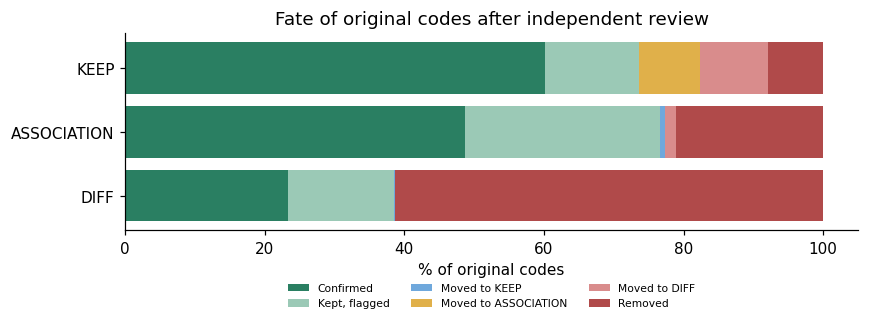

,Original,Revised,Net change,Added (new to condition),Moved in,Moved out,Removed
KEEP,2018,2035,17,536,12,372,159
ASSOCIATION,1327,1591,264,399,175,31,279
DIFF,1495,1117,-378,322,219,3,916


Role-transition matrix (rows = original role, columns = revised role; "-" = not in solution):


Rev_Role,- (removed),ASSOCIATION,DIFF,KEEP
Orig_Role,,,,
- (added),0,399,322,536
ASSOCIATION,279,1017,21,10
DIFF,916,1,576,2
KEEP,159,174,198,1487


In [4]:
o = chg[chg.Orig_Role.notna()].copy()
o['Fate'] = np.select(
    [o.Status.eq('removed'), o.Status.eq('moved') & o.Rev_Role.eq('KEEP'), o.Status.eq('moved') & o.Rev_Role.eq('ASSOCIATION'),
     o.Status.eq('moved') & o.Rev_Role.eq('DIFF'), o.Flagged],
    ['Removed', 'Moved to KEEP', 'Moved to ASSOCIATION', 'Moved to DIFF', 'Kept, flagged'], 'Confirmed')
FATES = ['Confirmed', 'Kept, flagged', 'Moved to KEEP', 'Moved to ASSOCIATION', 'Moved to DIFF', 'Removed']
fate = pd.crosstab(o.Orig_Role, o.Fate).reindex(index=ROLES, columns=FATES, fill_value=0)
fate['Original total'] = fate.sum(axis=1)
display(fate)
fate_pct = fate[FATES].div(fate['Original total'], axis=0) * 100
display(fate_pct.round(1).add_suffix(' %'))

fig, ax = plt.subplots(figsize=(8, 3.2))
colors = ['#2a7f62', '#9bc9b6', '#6fa8dc', '#e0b04a', '#d98c8c', '#b04a4a']
left = np.zeros(3)
for f, c in zip(FATES, colors):
    ax.barh(ROLES, fate_pct[f], left=left, color=c, label=f); left += fate_pct[f].values
ax.invert_yaxis(); ax.set_xlabel('% of original codes'); ax.legend(ncol=3, fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.22), frameon=False)
ax.set_title('Fate of original codes after independent review'); plt.tight_layout(); plt.show()

tot = pd.DataFrame({
    'Original': {k: sum(len(O[(c, k)]) for c in CONDS) for k in ROLES},
    'Revised':  {k: sum(len(R[(c, k)]) for c in CONDS) for k in ROLES}})
tot['Net change'] = tot.Revised - tot.Original
tot['Added (new to condition)'] = [int(((chg.Status == 'added') & (chg.Rev_Role == k)).sum()) for k in ROLES]
tot['Moved in'] = [int(((chg.Status == 'moved') & (chg.Rev_Role == k)).sum()) for k in ROLES]
tot['Moved out'] = [int(((chg.Status == 'moved') & (chg.Orig_Role == k)).sum()) for k in ROLES]
tot['Removed'] = [int(((chg.Status == 'removed') & (chg.Orig_Role == k)).sum()) for k in ROLES]
display(tot)
print('Role-transition matrix (rows = original role, columns = revised role; "-" = not in solution):')
display(pd.crosstab(chg.Orig_Role.fillna('- (added)'), chg.Rev_Role.fillna('- (removed)')))

## 4. Agreement between original and revised
Metrics treat the revised solution as the reference and the original as the "prediction", using the same set-F1 convention as the manuscript (role-specific F1 per condition, then equal-weight mean of the three roles). Because the revised solution has **no empty cells**, the "excluded" and "empty-match-credit" conventions coincide here (see §7).

Cohen's κ is shown on two universes: the **fixed dictionary** (97,441 codes × conditions) and a **pair-specific union** (codes selected in either solution for that role, as in the manuscript's original κ implementation). Neither is an inter-rater estimate (see caveat).

In [5]:
def prf(a, b):
    tp = len(a & b); p = tp/len(a) if a else 0.0; r = tp/len(b) if b else 0.0
    f = 2*p*r/(p+r) if p+r else 0.0
    return p, r, f

def f1_cell(a, b, convention='historical'):
    if not a and not b: return 1.0 if convention == 'historical' else np.nan
    return prf(a, b)[2]

fam = lambda s: {x[:3] for x in s}

def cond_table(level='code'):
    rows = []
    for c in CONDS:
        row = {'Condition': c, 'Split': SPLIT[c]}
        for k in ROLES:
            a, b = (O[(c, k)], R[(c, k)]) if level == 'code' else (fam(O[(c, k)]), fam(R[(c, k)]))
            p, r, f = prf(a, b)
            row.update({f'{k}_n_orig': len(a), f'{k}_n_rev': len(b), f'{k}_P': p, f'{k}_R': r, f'{k}_F1': f,
                        f'{k}_Jaccard': len(a & b)/len(a | b) if a | b else np.nan})
        rows.append(row)
    t = pd.DataFrame(rows)
    t['EqualRole_F1'] = t[[f'{k}_F1' for k in ROLES]].mean(axis=1)
    return t
ct_code, ct_fam = cond_table('code'), cond_table('family')

def kappa(tp, fp, fn, n):
    tn = n - tp - fp - fn; po = (tp + tn)/n
    pe = ((tp+fp)*(tp+fn) + (fn+tn)*(fp+tn))/n**2
    return (po - pe)/(1 - pe) if pe < 1 else np.nan

def summary(conds):
    rows = []
    for k in ROLES:
        tp = sum(len(O[(c,k)] & R[(c,k)]) for c in conds); fp = sum(len(O[(c,k)] - R[(c,k)]) for c in conds)
        fn = sum(len(R[(c,k)] - O[(c,k)]) for c in conds)
        U = set().union(*[O[(c,k)] | R[(c,k)] for c in conds])
        t = ct_code[ct_code.Condition.isin(conds)]; tf = ct_fam[ct_fam.Condition.isin(conds)]
        rows.append({'Role': k, 'Conditions': len(conds), 'Orig codes': tp+fp, 'Rev codes': tp+fn,
                     'Micro precision (orig confirmed)': tp/(tp+fp), 'Micro recall (orig found)': tp/(tp+fn),
                     'Micro F1': 2*tp/(2*tp+fp+fn), 'Macro F1 (per-condition mean)': t[f'{k}_F1'].mean(),
                     'Macro F1, 3-char category': tf[f'{k}_F1'].mean(),
                     'κ fixed dictionary': kappa(tp, fp, fn, len(conds)*len(DICT)),
                     'κ pair-union': kappa(tp, fp, fn, len(conds)*len(U))})
    s = pd.DataFrame(rows).set_index('Role')
    s.loc['Equal-role mean'] = s.drop(columns=['Conditions','Orig codes','Rev codes']).mean().reindex(s.columns)
    return s

agree_all  = summary(CONDS)
agree_priv = summary([c for c in CONDS if SPLIT[c] == 'Private'])
agree_pub  = summary([c for c in CONDS if SPLIT[c] == 'Public'])
for name, t in [('All 23 conditions', agree_all), ('Private split (17)', agree_priv), ('Public split (6)', agree_pub)]:
    display(Markdown(f'**{name}**')); display(t)

**All 23 conditions**

,Conditions,Orig codes,Rev codes,Micro precision (orig confirmed),Micro recall (orig found),Micro F1,Macro F1 (per-condition mean),"Macro F1, 3-char category",κ fixed dictionary,κ pair-union
Role,,,,,,,,,,
KEEP,23.000,"2,018.000","2,035.000",0.737,0.731,0.734,0.725,0.761,0.734,0.724
ASSOCIATION,23.000,"1,327.000","1,591.000",0.766,0.639,0.697,0.615,0.590,0.697,0.685
DIFF,23.000,"1,495.000","1,117.000",0.385,0.516,0.441,0.293,0.284,0.441,0.422
Equal-role mean,NaN,NaN,NaN,0.630,0.629,0.624,0.544,0.545,0.624,0.610


**Private split (17)**

,Conditions,Orig codes,Rev codes,Micro precision (orig confirmed),Micro recall (orig found),Micro F1,Macro F1 (per-condition mean),"Macro F1, 3-char category",κ fixed dictionary,κ pair-union
Role,,,,,,,,,,
KEEP,17.000,"1,500.000","1,318.000",0.831,0.946,0.885,0.795,0.777,0.885,0.878
ASSOCIATION,17.000,"1,090.000","1,194.000",0.832,0.760,0.794,0.686,0.679,0.794,0.782
DIFF,17.000,"1,070.000",623.000,0.263,0.451,0.332,0.302,0.294,0.332,0.308
Equal-role mean,NaN,NaN,NaN,0.642,0.719,0.670,0.594,0.583,0.670,0.656


**Public split (6)**

,Conditions,Orig codes,Rev codes,Micro precision (orig confirmed),Micro recall (orig found),Micro F1,Macro F1 (per-condition mean),"Macro F1, 3-char category",κ fixed dictionary,κ pair-union
Role,,,,,,,,,,
KEEP,6.000,518.000,717.000,0.463,0.335,0.389,0.528,0.715,0.388,0.320
ASSOCIATION,6.000,237.000,397.000,0.464,0.277,0.347,0.414,0.340,0.347,0.276
DIFF,6.000,425.000,494.000,0.694,0.597,0.642,0.265,0.256,0.642,0.579
Equal-role mean,NaN,NaN,NaN,0.541,0.403,0.459,0.402,0.437,0.459,0.392


## 5. Condition-level view

,Condition,Split,KEEP_F1,ASSOCIATION_F1,DIFF_F1,EqualRole_F1
0,Enlarged Mediastinum,Public,0.292,0.199,0.000,0.164
1,Hematemesis,Private,0.543,0.000,0.000,0.181
2,Intracranial Pressure,Public,0.383,0.356,0.000,0.246
3,Nasopharyngeal Carcinoma,Private,0.452,0.000,0.724,0.392
4,Chronic Obstructive Pulmonary Disease,Public,0.438,0.000,0.870,0.436
5,CKD,Private,0.914,0.421,0.000,0.445
6,Hypoparathyroidism,Private,0.444,0.923,0.000,0.456
7,Pneumonia,Private,0.711,0.667,0.000,0.459
8,Hyperthyroidism,Private,0.571,0.903,0.000,0.491
9,Epistaxis,Public,0.769,0.713,0.000,0.494


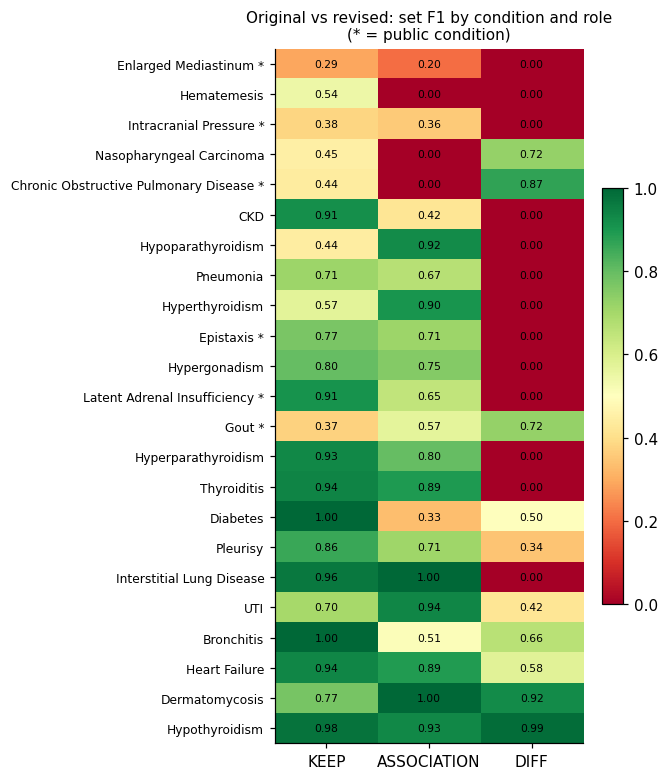

Status,added,moved,removed,unchanged,Original codes,Revised codes,"Churn (1-Jaccard of code sets, any role)",Split
Condition,,,,,,,,
Enlarged Mediastinum,94,27,298,46,371,167,0.901,Public
Pneumonia,115,38,647,184,869,337,0.813,Private
Intracranial Pressure,130,3,20,43,66,176,0.781,Public
Hyperthyroidism,7,12,230,110,352,129,0.694,Private
Hematemesis,18,55,8,41,104,114,0.664,Private
Gout,438,135,6,368,509,941,0.611,Public
Hyperparathyroidism,34,1,0,35,36,70,0.500,Private
Pleurisy,31,3,47,91,141,125,0.471,Private
Bronchitis,66,0,0,75,75,141,0.468,Private


In [6]:
cols = ['Condition','Split'] + [f'{k}_F1' for k in ROLES] + ['EqualRole_F1']
view = ct_code[cols].sort_values('EqualRole_F1')
display(view.reset_index(drop=True))

M = ct_code.set_index('Condition').loc[view.Condition, [f'{k}_F1' for k in ROLES]]
fig, ax = plt.subplots(figsize=(6.2, 7.2))
im = ax.imshow(M.values, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(3)); ax.set_xticklabels(ROLES); ax.set_yticks(range(len(M)))
ax.set_yticklabels([f'{c}{" *" if SPLIT[c]=="Public" else ""}' for c in M.index], fontsize=8)
for i in range(M.shape[0]):
    for j in range(3): ax.text(j, i, f'{M.values[i,j]:.2f}', ha='center', va='center', fontsize=7)
ax.set_title('Original vs revised: set F1 by condition and role\n(* = public condition)', fontsize=10)
plt.colorbar(im, shrink=0.6); plt.tight_layout(); plt.show()

# Churn = share of the union that differs between original and revised
cnt = chg.groupby(['Condition','Status']).size().unstack(fill_value=0).reindex(CONDS, fill_value=0)
for s_ in ['unchanged','moved','removed','added']:
    if s_ not in cnt: cnt[s_] = 0
cnt['Original codes'] = cnt.unchanged + cnt.moved + cnt.removed
cnt['Revised codes'] = cnt.unchanged + cnt.moved + cnt.added
cnt['Churn (1-Jaccard of code sets, any role)'] = 1 - cnt.unchanged / (cnt.unchanged + cnt.moved + cnt.removed + cnt.added)
cnt['Split'] = cnt.index.map(SPLIT)
display(cnt.sort_values('Churn (1-Jaccard of code sets, any role)', ascending=False))

In [7]:
# Concentration: which conditions carry the changes?
chs = chg[chg.Status != 'unchanged'].groupby('Condition').size().sort_values(ascending=False)
share = (chs / chs.sum()).cumsum()
display(pd.DataFrame({'changes': chs, 'cumulative share': share}).head(8))

# Removed DIFF codes: how concentrated?
rd = chg[(chg.Status == 'removed') & (chg.Orig_Role == 'DIFF')].groupby('Condition').size()
print('Removed DIFF codes by condition:', rd.to_dict(), '-> total', rd.sum(), 'of', sum(len(O[(c,'DIFF')]) for c in CONDS), 'original DIFF codes')
dd = pd.DataFrame({'orig DIFF': {c: len(O[(c,'DIFF')]) for c in rd.index}, 'rev DIFF': {c: len(R[(c,'DIFF')]) for c in rd.index},
                   'overlap': {c: len(O[(c,'DIFF')] & R[(c,'DIFF')]) for c in rd.index}})
display(dd)

# Split comparison of changes
sp = chg.groupby(['Split','Status']).size().unstack(fill_value=0)
sp['orig'] = sp.unchanged + sp.moved + sp.removed
display(pd.concat([sp, (sp[['moved','removed','added']].div(sp.orig, axis=0)).add_suffix(' / orig')], axis=1))

,changes,cumulative share
Condition,,
Pneumonia,800,0.265
Gout,579,0.457
Enlarged Mediastinum,419,0.596
Hyperthyroidism,249,0.678
Intracranial Pressure,153,0.729
Chronic Obstructive Pulmonary Disease,101,0.763
Hematemesis,81,0.790
Pleurisy,81,0.816


Removed DIFF codes by condition: {'Enlarged Mediastinum': 130, 'Hyperthyroidism': 203, 'Pneumonia': 583} -> total 916 of 1495 original DIFF codes


,orig DIFF,rev DIFF,overlap
Enlarged Mediastinum,130,10,0
Hyperthyroidism,203,6,0
Pneumonia,583,84,0


Status,added,moved,removed,unchanged,orig,moved / orig,removed / orig,added / orig
Split,,,,,,,,
Private,494,206,1019,2435,3660,0.056,0.278,0.135
Public,763,200,335,645,1180,0.169,0.284,0.647


## 6. Why were codes changed?
The log holds 3,899 rows but only a few hundred distinct reasons: most decisions were made **per block** of codes. We (a) group reasons into transparent keyword themes (a heuristic; check the unclassified remainder) and (b) measure how much of the revision comes from a handful of blocks.

In [8]:
THEMES = [
 ('Housekeeping: duplicate entry',          r'duplicate entry'),
 ('Opposite state / different disease',     r'opposite|different disease|hypo(parathyroidism|gonadism|thyroidism)\b.*opposite'),
 ('Off-topic / no clinical link',           r'off-topic|no link|no specific|no pleural|no mediastinal|unrelated|has no |have no |only d44|directly relevant'),
 ('Missing direct code(s)',                 r'missing|own icd|was missing|were missing|direct .*diagnos'),
 ('Differential diagnosis',                 r'differential|mimic'),
 ('Cause / risk factor / comorbidity',      r'\bcause|risk factor|risk lesion|predispos|comorbid|trigger|precipitat|frequent cause|commonest|aetiolog|etiolog|established|behind|presenting sign|usual misdiagnosis'),
 ('Manifestation / complication / symptom', r'complication|manifestation|symptom|consequence'),
 ('Header / unspecified / non-specific',    r'header|unspecified|non-specific|not specific'),
 ('Weak / indirect / arguable role',        r'weak|indirect|proxy|rarely|broad block|some coders|better seen|many coders|acceptable'),
 ('Not the target condition (other entity)',r'\bnot\b|are .* not |is .* not '),
]
def theme(reason):
    r = reason.lower()
    for name, pat in THEMES:
        if re.search(pat, r): return name
    return 'Other / unclassified'

log2 = log.copy()
log2['Theme'] = log2.Reason.map(theme)
log2['Kind'] = np.where(log2.Action == 'flagged', 'flagged (kept)', log2.Action)
tt = pd.crosstab(log2.Theme, log2.Kind)
tt['Total'] = tt.sum(axis=1)
display(tt.sort_values('Total', ascending=False))
print('Unclassified rows:', int((log2.Theme == 'Other / unclassified').sum()), 'of', len(log2))
display(log2[log2.Theme == 'Other / unclassified'].Reason.value_counts().head(10))

Kind,added,flagged (kept),moved,removed,Total
Theme,,,,,
Off-topic / no clinical link,0,20,0,1201,1221
Differential diagnosis,297,249,212,0,758
Cause / risk factor / comorbidity,318,225,107,0,650
Missing direct code(s),474,0,0,0,474
Other / unclassified,163,40,12,9,224
Weak / indirect / arguable role,0,211,0,0,211
Not the target condition (other entity),0,16,0,98,114
Manifestation / complication / symptom,5,23,67,18,113
Header / unspecified / non-specific,0,65,0,15,80


Unclassified rows: 224 of 3899


,count
Reason,
"atrial fibrillation, mitral and aortic valve disease, pulmonary hypertension due to left heart disease and cor pulmonale",29
"Cushing's syndrome, prediabetes, insulin / oral / injectable antidiabetic use, metabolic syndrome, obesity and infant of a diabetic mother",24
"thymic and mediastinal neoplasms (benign, uncertain, secondary, primary mediastinal large B-cell lymphoma), thymic disease and mediastinal cyst - diseases that are the mediastinum enlarging",22
"COVID-19, acute respiratory failure, hypoxaemia and neutropenia",14
"MEN syndromes, vitamin D deficiency, osteoporosis and CKD stage 3-5 (secondary hyperparathyroidism)",13
"pneumonic plague, pulmonary tularaemia and anthrax, and pulmonary endemic mycoses (consistent with the pulmonary mycoses already in KEEP)",12
"gastric varices, portal hypertension, cirrhosis, acute blood-loss anaemia, anticoagulant and aspirin use",9
"whooping cough, measles, rubella, salmonella, gonococcal and ascaris pneumonia - ""with pneumonia"" codes in other chapters",9
"catheter-associated UTI (infection due to urinary catheter, initial encounter)",9


Blocks: 139 | codes changed: 3017
  top  3 blocks =  1190 codes = 39.4% of all changes
  top  5 blocks =  1450 codes = 48.1% of all changes
  top 10 blocks =  1794 codes = 59.5% of all changes
  top 20 blocks =  2141 codes = 71.0% of all changes


,Condition,Action,Original_Class,Revised_Class,Reason,codes,cum share of all changes
0,Pneumonia,removed,DIFF,,"off-topic block: lymphoma, leukaemia, myeloma and myelodysplasia are not differentials of pneumonia",583,0.193
1,Gout,added,,KEEP,chronic (tophaceous) gout has its own ICD-10-CM category M1A and was missing entirely,404,0.327
2,Hyperthyroidism,removed,DIFF,,"off-topic block: hypertension, myocardial infarction and stroke are not differentials of hyperthyroidism",203,0.394
3,Enlarged Mediastinum,removed,DIFF,,"off-topic block: influenza, pneumonia, bronchitis, COPD and asthma do not mimic mediastinal enlargement",130,0.438
4,Gout,moved,KEEP,DIFF,"other crystal arthropathies (CPPD / pseudogout) are the main differential of gout, not gout",130,0.481
5,Enlarged Mediastinum,removed,ASSOCIATION,,"off-topic block of respiratory codes (airway dust disease, aspiration, ARDS, oedema, eosinophilia, empyema, pneumoth...",118,0.520
6,Pneumonia,added,,DIFF,"heart failure / pulmonary oedema, pulmonary embolism, atelectasis, ILD, lung cancer and pulmonary TB - the standard ...",68,0.542
7,Pneumonia,removed,ASSOCIATION,,"haemolytic, aplastic-type and other anaemias have no link with pneumonia (sickle-cell disease D57 and hyposplenism D...",63,0.563
8,Intracranial Pressure,added,,KEEP,"compression of brain, cerebral oedema and traumatic cerebral oedema are direct raised-ICP diagnoses and were missing",48,0.579
9,Pleurisy,removed,ASSOCIATION,,tuberculosis of the nervous system and of other organs has no pleural link,47,0.595


'Off-topic' removals: 1034 = 76.4% of all removals
Condition             Original_Class
Enlarged Mediastinum  ASSOCIATION       118
                      DIFF              130
Hyperthyroidism       DIFF              203
Pneumonia             DIFF              583
dtype: int64


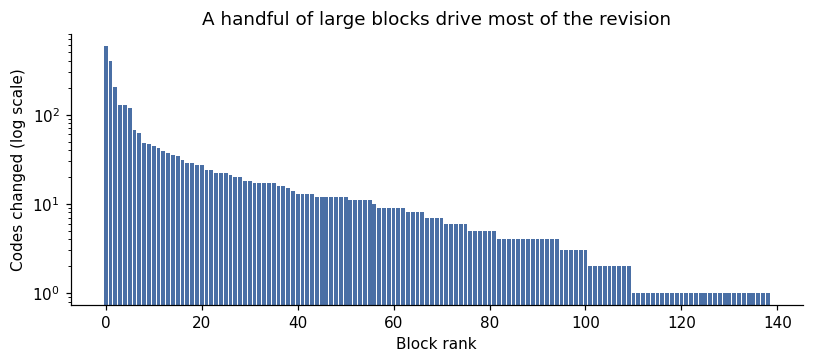

In [9]:
# Concentration in blocks (one block = identical reason text within a condition and action)
real2 = log2[(log2.Action != 'flagged') & ~log2.Reason.str.contains('duplicate entry')]
blk = real2.groupby(['Condition','Action','Original_Class','Revised_Class','Reason']).size().rename('codes').reset_index()
blk = blk.sort_values('codes', ascending=False).reset_index(drop=True)
blk['cum share of all changes'] = blk.codes.cumsum() / blk.codes.sum()
print('Blocks:', len(blk), '| codes changed:', blk.codes.sum())
for n in [3, 5, 10, 20]:
    print(f'  top {n:>2} blocks = {blk.codes.head(n).sum():>5} codes = {blk.codes.head(n).sum()/blk.codes.sum():.1%} of all changes')
display(blk.head(12))

off = real2[real2.Reason.str.contains('off-topic')]
print(f"'Off-topic' removals: {len(off)} = {len(off)/ (real2.Action=='removed').sum():.1%} of all removals")
print(off.groupby(['Condition','Original_Class']).size())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(range(len(blk)), blk.codes, color='#4a6fa5'); ax.set_yscale('log')
ax.set_xlabel('Block rank'); ax.set_ylabel('Codes changed (log scale)')
ax.set_title('A handful of large blocks drive most of the revision'); plt.tight_layout(); plt.show()

### 4b. Robustness: how much do the largest blocks drive the agreement figures?
Pooled (micro) agreement is sensitive to a few very large decisions (e.g. one 404-code Gout block). Here the top-N blocks of §6 are removed from **both** solutions and micro-F1 is recomputed. Per-condition (macro) F1 is less exposed to this.

In [10]:
def micro_f1_excluding(top_n):
    drop = set()
    if top_n:
        keys = blk.head(top_n)[['Condition','Action','Original_Class','Revised_Class','Reason']]
        sub = real2.merge(keys, on=list(keys.columns)); drop = set(zip(sub.Condition, sub.Code))
    out = {}
    for k in ROLES:
        tp = fp = fn = 0
        for c in CONDS:
            a = {x for x in O[(c,k)] if (c,x) not in drop}; b = {x for x in R[(c,k)] if (c,x) not in drop}
            tp += len(a & b); fp += len(a - b); fn += len(b - a)
        out[k] = 2*tp/(2*tp+fp+fn)
    return out
rob = pd.DataFrame({f'drop top {n} blocks' if n else 'all codes': micro_f1_excluding(n) for n in [0, 1, 3, 5, 10]}).T
display(rob)

,KEEP,ASSOCIATION,DIFF
all codes,0.734,0.697,0.441
drop top 1 blocks,0.734,0.697,0.568
drop top 3 blocks,0.815,0.697,0.631
drop top 5 blocks,0.845,0.697,0.736
drop top 10 blocks,0.857,0.756,0.769


## 7. Empty roles (reviewer question: why is DIFF empty for 10 of 23 conditions?)
The manuscript noted 10 empty DIFF and 3 empty ASSOCIATION cells in the original, which drove the empty-match-credit effect. Did the reviewer treat these as genuine absences?

In [11]:
rows = []
for c in CONDS:
    for k in ['ASSOCIATION', 'DIFF']:
        if not O[(c, k)] or not R[(c, k)]:
            rows.append({'Condition': c, 'Split': SPLIT[c], 'Role': k, 'Orig n': len(O[(c,k)]), 'Rev n': len(R[(c,k)])})
em = pd.DataFrame(rows)
print('Empty cells  -> original:', int(sum(not O[(c,k)] for c in CONDS for k in ROLES)),
      '| revised:', int(sum(not R[(c,k)] for c in CONDS for k in ROLES)))
print(em.groupby('Role').agg(cells=('Condition','size')).T.to_string())
display(em.sort_values(['Role','Condition']).reset_index(drop=True))
filled = em[(em['Orig n'] == 0)]
ex = chg[(chg.Status == 'added')].merge(filled[['Condition','Role']], left_on=['Condition','Rev_Role'], right_on=['Condition','Role'])
print('Codes the reviewer added to previously empty cells:', len(ex))
display(ex.groupby(['Role','Condition']).agg(codes=('Code','size'), reason=('Reason', lambda s: ' || '.join(pd.unique(s))[:160])).reset_index().sort_values(['Role','Condition']))

Empty cells  -> original: 13 | revised: 0
Role   ASSOCIATION  DIFF
cells            3    10


,Condition,Split,Role,Orig n,Rev n
0,Chronic Obstructive Pulmonary Disease,Public,ASSOCIATION,0,60
1,Hematemesis,Private,ASSOCIATION,0,64
2,Nasopharyngeal Carcinoma,Private,ASSOCIATION,0,11
3,CKD,Private,DIFF,0,6
4,Epistaxis,Public,DIFF,0,3
5,Hematemesis,Private,DIFF,0,3
6,Hypergonadism,Private,DIFF,0,8
7,Hyperparathyroidism,Private,DIFF,0,21
8,Hypoparathyroidism,Private,DIFF,0,9
9,Interstitial Lung Disease,Private,DIFF,0,41


Codes the reviewer added to previously empty cells: 127


,Role,Condition,codes,reason
0,ASSOCIATION,Chronic Obstructive Pulmonary Disease,31,"nicotine dependence (current or past) - the main cause of COPD || pulmonary hypertension due to lung disease, chroni..."
1,ASSOCIATION,Hematemesis,9,"gastric varices, portal hypertension, cirrhosis, acute blood-loss anaemia, anticoagulant and aspirin use"
2,ASSOCIATION,Nasopharyngeal Carcinoma,11,"EBV infection (main aetiological factor), cervical nodal metastasis and serous otitis media (classic presenting sign)"
3,DIFF,Epistaxis,1,haematemesis - swallowed blood from a posterior nosebleed is a known mimic
4,DIFF,Hematemesis,3,"haemoptysis, swallowed blood from epistaxis and neonatal swallowed maternal blood - the classic mimics of haematemesis"
5,DIFF,Hyperparathyroidism,21,"bone metastases, myeloma, sarcoidosis and vitamin D toxicity - the main non-parathyroid causes of hypercalcaemia"
6,DIFF,Hypoparathyroidism,3,vitamin D deficiency / rickets - the main differential of hypocalcaemia
7,DIFF,Interstitial Lung Disease,35,heart failure and pneumonia - the commonest mimics of interstitial shadowing
8,DIFF,Intracranial Pressure,7,"CSF leak / post-lumbar-puncture reaction - intracranial HYPOtension, the main headache differential"
9,DIFF,Latent Adrenal Insufficiency,2,SIADH / hyponatraemia of other cause - main differential of the hyponatraemia seen in adrenal insufficiency


## 8. Structure of the original solution
Does the original respect ICD hierarchy (whole categories rather than scattered codes)? *Family completeness* = share of 3-character families selected for a condition-role in which **every** dictionary code of that family is included.

In [12]:
fam_size = collections.Counter(c[:3] for c in DICT)
def completeness(S):
    rows = []
    for (c, k), codes in S.items():
        for f in fam(codes):
            n = sum(1 for x in codes if x.startswith(f)); rows.append((c, k, f, n, fam_size[f], n/fam_size[f]))
    return pd.DataFrame(rows, columns=['Condition','Role','Family','n_sel','n_dict','coverage'])
co, cr = completeness(O), completeness(R)
comp = pd.DataFrame({
  'Orig: families': co.groupby('Role').size(), 'Orig: fully covered %': co.groupby('Role').apply(lambda d: (d.coverage == 1).mean()*100),
  'Orig: partly covered (<50%) %': co.groupby('Role').apply(lambda d: (d.coverage < .5).mean()*100),
  'Rev: families': cr.groupby('Role').size(), 'Rev: fully covered %': cr.groupby('Role').apply(lambda d: (d.coverage == 1).mean()*100),
  'Rev: partly covered (<50%) %': cr.groupby('Role').apply(lambda d: (d.coverage < .5).mean()*100)}).reindex(ROLES)
display(comp)

# Original codes that were removed: which ICD chapters (first letter) do they come from?
ch = chg[chg.Orig_Role.notna()].assign(Chapter=lambda d: d.Code.str[0])
tbl = ch.groupby(['Orig_Role','Chapter']).agg(orig=('Code','size'), removed=('Status', lambda s: (s=='removed').sum())).reset_index()
tbl['removed %'] = tbl.removed / tbl.orig * 100
display(tbl[tbl.orig >= 40].sort_values(['Orig_Role','removed %'], ascending=[True, False]).groupby('Orig_Role').head(5))

/tmp/ipykernel_1660/2886151720.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'Orig: families': co.groupby('Role').size(), 'Orig: fully covered %': co.groupby('Role').apply(lambda d: (d.coverage == 1).mean()*100),
/tmp/ipykernel_1660/2886151720.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'Orig: partly covered (<50%) %': co.groupby('Role').apply(lambda d: (d.coverage < .5).mean()*100),
/tmp/ip

,Orig: families,Orig: fully covered %,Orig: partly covered (<50%) %,Rev: families,Rev: fully covered %,Rev: partly covered (<50%) %
Role,,,,,,
KEEP,166,84.337,15.663,187,48.663,42.246
ASSOCIATION,162,88.272,11.728,238,55.462,34.874
DIFF,106,99.057,0.943,147,60.544,36.054


,Orig_Role,Chapter,orig,removed,removed %
7,ASSOCIATION,J,254,118,46.457
0,ASSOCIATION,A,102,47,46.078
3,ASSOCIATION,D,206,63,30.583
4,ASSOCIATION,E,232,22,9.483
9,ASSOCIATION,M,109,5,4.587
18,DIFF,I,203,203,100.000
15,DIFF,C,645,570,88.372
19,DIFF,J,283,130,45.936
14,DIFF,B,108,0,0.000
17,DIFF,E,44,0,0.000


## 9. Items kept but flagged as debatable
The reviewer kept 871 codes unchanged but flagged them. These mark where a second reviewer is *likely to disagree* and therefore where the benchmark's residual label noise sits.

In [13]:
fl = chg[chg.Flagged & (chg.Status == 'unchanged')].copy()
fl['Theme'] = fl.Reason.map(theme)
display(pd.crosstab(fl.Orig_Role, fl.Theme))
fc = fl.groupby('Condition').size().rename('flagged').to_frame()
fc['revised codes'] = [sum(len(R[(c,k)]) for k in ROLES) for c in fc.index]
fc['flagged %'] = fc.flagged / fc['revised codes'] * 100
display(fc.sort_values('flagged %', ascending=False).head(10))
unc = pd.DataFrame({'Revised codes': {k: sum(len(R[(c,k)]) for c in CONDS) for k in ROLES},
                    'Flagged (kept)': fl.groupby('Orig_Role').size().reindex(ROLES)})
unc['Flagged %'] = unc['Flagged (kept)'] / unc['Revised codes'] * 100
display(unc)

Theme,Cause / risk factor / comorbidity,Differential diagnosis,Header / unspecified / non-specific,Manifestation / complication / symptom,Not the target condition (other entity),Off-topic / no clinical link,Opposite state / different disease,Other / unclassified,Weak / indirect / arguable role
Orig_Role,,,,,,,,,
ASSOCIATION,73,65,12,12,0,20,0,21,168
DIFF,0,184,0,0,0,0,22,0,22
KEEP,152,0,53,11,16,0,0,19,21


,flagged,revised codes,flagged %
Condition,,,
Dermatomycosis,98,154,63.636
Thyroiditis,36,58,62.069
CKD,122,216,56.481
Epistaxis,34,64,53.125
Hypothyroidism,53,102,51.961
UTI,101,222,45.495
Hypoparathyroidism,46,104,44.231
Latent Adrenal Insufficiency,16,41,39.024
Hypergonadism,22,60,36.667


,Revised codes,Flagged (kept),Flagged %
KEEP,2035,272,13.366
ASSOCIATION,1591,371,23.319
DIFF,1117,228,20.412


## 10. Scorecard: evaluation of the original solution
Rule-of-thumb bands on set F1 versus the revised reference (≥ 0.80 *strong*, 0.60–0.80 *moderate*, < 0.60 *weak*). The bands are a reporting convention, not a validated standard.

In [14]:
sc = pd.DataFrame(index=ROLES)
sc['Original codes'] = fate['Original total']
sc['Confirmed (unflagged) %'] = fate_pct['Confirmed']
sc['Kept but flagged %'] = fate_pct['Kept, flagged']
sc['Moved to another role %'] = fate_pct[['Moved to KEEP','Moved to ASSOCIATION','Moved to DIFF']].sum(axis=1)
sc['Removed %'] = fate_pct['Removed']
sc['Missing (added by reviewer) as % of revised'] = [tot.loc[k,'Added (new to condition)'] / tot.loc[k,'Revised'] * 100 for k in ROLES]
sc['Empty cells original → revised'] = [f"{sum(not O[(c,k)] for c in CONDS)} → {sum(not R[(c,k)] for c in CONDS)}" for k in ROLES]
sc['Macro F1 vs revised'] = agree_all.loc[ROLES, 'Macro F1 (per-condition mean)']
sc['Macro F1, 3-char category'] = agree_all.loc[ROLES, 'Macro F1, 3-char category']
sc['κ (pair-union)'] = agree_all.loc[ROLES, 'κ pair-union']
sc['Band'] = pd.cut(sc['Macro F1 vs revised'], [-1, .6, .8, 1.01], labels=['weak', 'moderate', 'strong']).astype(str)
display(sc.T)
sc.to_csv(OUT_DIR/'scorecard.csv')

,KEEP,ASSOCIATION,DIFF
Original codes,2018,1327,1495
Confirmed (unflagged) %,60.208,48.681,23.278
Kept but flagged %,13.479,27.958,15.251
Moved to another role %,18.434,2.336,0.201
Removed %,7.879,21.025,61.271
Missing (added by reviewer) as % of revised,26.339,25.079,28.827
Empty cells original → revised,0 → 0,3 → 0,10 → 0
Macro F1 vs revised,0.725,0.615,0.293
"Macro F1, 3-char category",0.761,0.590,0.284
κ (pair-union),0.724,0.685,0.422


## 11. What does the revision do to benchmark scoring?
(a) **Original solution as a pseudo-system.** Scoring the original against the revised reference, under the manuscript's two conventions, gives a human-curated *reference-to-reference* benchmark for the system scores in the paper (non-blind, so an upper bound).  
(b) **Re-scoring the six submitted systems** against both references. Set `PRED_DIR` below to a folder with one CSV per system (same columns as `solution.csv`). Placeholders such as "Not Applicable" are parsed as empty sets, and the cell asserts that every predicted token is a dictionary code.

In [15]:
def score(pred, ref, conds, convention):
    out = {}
    for k in ROLES:
        v = [f1_cell(pred[(c,k)], ref[(c,k)], convention) for c in conds]
        out[k] = np.nanmean(v) if not all(np.isnan(v)) else 0.0
    out['Equal-role mean'] = np.mean([out[k] for k in ROLES]); return out

rows = []
for split, conds in [('Private (17)', [c for c in CONDS if SPLIT[c]=='Private']), ('Public (6)', [c for c in CONDS if SPLIT[c]=='Public']), ('All (23)', CONDS)]:
    for conv in ['historical', 'excluded']:
        s_ = score(O, R, conds, conv); rows.append({'Split': split, 'Convention': conv, **s_})
display(pd.DataFrame(rows))
print('Note: the two conventions coincide because the revised reference has no empty cells (and an empty original cell against a non-empty revised cell scores 0 under both).')
print('Manuscript reference points (private split, systems vs ORIGINAL reference): KEEP F1 0.517-0.610; equal-role mean 0.172-0.215.')

,Split,Convention,KEEP,ASSOCIATION,DIFF,Equal-role mean
0,Private (17),historical,0.795,0.686,0.302,0.594
1,Private (17),excluded,0.795,0.686,0.302,0.594
2,Public (6),historical,0.528,0.414,0.265,0.402
3,Public (6),excluded,0.528,0.414,0.265,0.402
4,All (23),historical,0.725,0.615,0.293,0.544
5,All (23),excluded,0.725,0.615,0.293,0.544


Note: the two conventions coincide because the revised reference has no empty cells (and an empty original cell against a non-empty revised cell scores 0 under both).
Manuscript reference points (private split, systems vs ORIGINAL reference): KEEP F1 0.517-0.610; equal-role mean 0.172-0.215.


In [16]:
PRED_DIR = Path('predictions')

if PRED_DIR is None:
    print('PRED_DIR not set: skipping system re-scoring.')
else:
    PRED_DIR = Path(PRED_DIR); res = []
    for f in sorted(PRED_DIR.glob('*.csv')):
        p = pd.read_csv(f, keep_default_na=False); P = {(r.Condition, k): set(parse(r[k])) for _, r in p.iterrows() for k in ROLES}
        P = {(c, k): P.get((c, k), set()) for c in CONDS for k in ROLES}
        bad = set().union(*P.values()) - set(DICT)
        assert not bad, f'{f.name}: {len(bad)} predicted tokens are not dictionary codes, e.g. {sorted(bad)[:5]}'
        for split, conds in [('Private', [c for c in CONDS if SPLIT[c]=='Private']), ('All', CONDS)]:
            for refname, ref in [('original', O), ('revised', R)]:
                res.append({'System': f.stem, 'Split': split, 'Reference': refname, **score(P, ref, conds, 'excluded')})
    res = pd.DataFrame(res); display(res)
    piv = res[res.Split == 'Private'].pivot(index='System', columns='Reference', values='Equal-role mean')
    piv['rank orig'] = piv.original.rank(ascending=False); piv['rank rev'] = piv.revised.rank(ascending=False)
    display(piv); print('Spearman rank correlation:', piv['rank orig'].corr(piv['rank rev'], method='spearman'))

,System,Split,Reference,KEEP,ASSOCIATION,DIFF,Equal-role mean
0,Alan T Andrea,Private,original,0.602,0.000,0.000,0.201
1,Alan T Andrea,Private,revised,0.690,0.001,0.000,0.230
2,Alan T Andrea,All,original,0.625,0.000,0.000,0.208
3,Alan T Andrea,All,revised,0.622,0.000,0.000,0.208
4,Md Raihan,Private,original,0.582,0.000,0.000,0.194
5,Md Raihan,Private,revised,0.611,0.000,0.000,0.204
6,Md Raihan,All,original,0.539,0.000,0.000,0.180
7,Md Raihan,All,revised,0.568,0.000,0.000,0.189
8,Monash AIM,Private,original,0.517,0.000,0.000,0.172
9,Monash AIM,Private,revised,0.577,0.000,0.000,0.192


Reference,original,revised,rank orig,rank rev
System,,,,
Alan T Andrea,0.201,0.230,4.000,4.000
Md Raihan,0.194,0.204,5.000,5.000
Monash AIM,0.172,0.192,6.000,6.000
NTUA,0.215,0.243,1.000,3.000
Ngọc Hưng Nguyễn,0.201,0.243,3.000,2.000
Yingfali,0.203,0.243,2.000,1.000


Spearman rank correlation: 0.8285714285714287


### 11b. Sensitivity: scoring with and without the largest blocks and the flagged codes
The six systems are re-scored (primary convention, jointly empty cells excluded) under five variants. In each variant the listed *(condition, code)* pairs are dropped from the predictions **and** from both references, so systems are neither rewarded nor penalised for them:

* **all codes** (must reproduce §11),
* **flagged codes ignored** (the 871 codes kept but flagged as debatable),
* **top-3 blocks ignored** and **top-10 blocks ignored** (the largest decision blocks of §6),
* **flagged + top-10 blocks ignored**.

This is a descriptive sensitivity analysis; it does not replace the primary scores on the frozen original reference.

In [17]:
priv = [c for c in CONDS if SPLIT[c] == 'Private']

def load_systems(pred_dir):
    out = {}
    for f in sorted(Path(pred_dir).glob('*.csv')):
        p = pd.read_csv(f, keep_default_na=False)
        P = {(r.Condition, k): set(parse(r[k])) for _, r in p.iterrows() for k in ROLES}
        out[f.stem] = {(c, k): P.get((c, k), set()) for c in CONDS for k in ROLES}
    return out

def block_pairs(top_n):
    """(condition, code) pairs that belong to the top-N decision blocks of section 6."""
    if not top_n: return set()
    keys = blk.head(top_n)[['Condition', 'Action', 'Original_Class', 'Revised_Class', 'Reason']]
    sub = real2.merge(keys, on=list(keys.columns))
    return set(zip(sub.Condition, sub.Code))

FLAG_PAIRS = set(flagged_keys)            # codes kept in place but flagged as debatable (871)

def drop(S, pairs):
    return {key: {x for x in v if (key[0], x) not in pairs} for key, v in S.items()}

if PRED_DIR is None:
    print('PRED_DIR not set: skipping sensitivity re-scoring.')
else:
    SYS = load_systems(PRED_DIR)
    VARIANTS = {'all codes': set(),
                'flagged codes ignored': FLAG_PAIRS,
                'top-3 blocks ignored': block_pairs(3),
                'top-10 blocks ignored': block_pairs(10),
                'flagged + top-10 blocks ignored': FLAG_PAIRS | block_pairs(10)}
    print({k: len(v) for k, v in VARIANTS.items()}, '(condition, code) pairs dropped from predictions and from both references')
    rows = []
    for vname, pairs in VARIANTS.items():
        for refname, ref in [('original', O), ('revised', R)]:
            refd = drop(ref, pairs)
            for sname, P in SYS.items():
                Pd = drop(P, pairs)
                for split, conds in [('Private', priv), ('All', CONDS)]:
                    rows.append({'Variant': vname, 'Reference': refname, 'System': sname, 'Split': split,
                                 **score(Pd, refd, conds, 'excluded')})
    sens = pd.DataFrame(rows)
    p_ = sens[sens.Split == 'Private']
    for role in ['KEEP', 'ASSOCIATION', 'DIFF', 'Equal-role mean']:
        display(Markdown(f'**Private split (17), {role} F1**'))
        display(p_.pivot_table(index=['Reference', 'Variant'], columns='System', values=role, sort=False))
    rk = (p_[p_.Reference == 'revised'].pivot(index='System', columns='Variant', values='Equal-role mean')
              .reindex(columns=list(VARIANTS)).rank(ascending=False, method='min'))
    display(Markdown('**Rank of each system (private, revised reference, equal-role mean; ties share the lowest rank)**')); display(rk)
    full = p_[(p_.Reference == 'revised')].pivot(index='System', columns='Variant', values='Equal-role mean').reindex(columns=list(VARIANTS))
    print('Spearman vs "all codes" (revised reference, private):',
          {v: round(full['all codes'].corr(full[v], method='spearman'), 3) for v in list(VARIANTS)[1:]})


{'all codes': 0, 'flagged codes ignored': 871, 'top-3 blocks ignored': 1190, 'top-10 blocks ignored': 1794, 'flagged + top-10 blocks ignored': 2665} (condition, code) pairs dropped from predictions and from both references


**Private split (17), KEEP F1**

System                                     Alan T Andrea  Md Raihan  Monash AIM  NTUA  Ngọc Hưng Nguyễn  Yingfali
Reference Variant                                                                                                    
original  all codes                                0.602      0.582       0.517 0.577                 0.604     0.610
          flagged codes ignored                    0.639      0.592       0.551 0.619                 0.644     0.635
          top-3 blocks ignored                     0.602      0.582       0.517 0.577                 0.604     0.610
          top-10 blocks ignored                    0.602      0.582       0.517 0.577                 0.604     0.610
          flagged + top-10 blocks ignored          0.639      0.592       0.551 0.619                 0.644     0.635
revised   all codes                                0.690      0.611       0.577 0.640                 0.729     0.729
          flagged codes ignored                    0.753      0.577       0.640 0.692                 0.808     0.807
          top-3 blocks ignored                     0.690      0.611       0.577 0.640                 0.729     0.729
          top-10 blocks ignored                    0.690      0.611       0.577 0.640                 0.729     0.729
          flagged + top-10 blocks ignored          0.753      0.577       0.640 0.692                 0.808     0.807

**Private split (17), ASSOCIATION F1**

System                                     Alan T Andrea  Md Raihan  Monash AIM  NTUA  Ngọc Hưng Nguyễn  Yingfali
Reference Variant                                                                                                    
original  all codes                                0.000      0.000       0.000 0.005                 0.000     0.000
          flagged codes ignored                    0.000      0.000       0.000 0.006                 0.000     0.000
          top-3 blocks ignored                     0.000      0.000       0.000 0.005                 0.000     0.000
          top-10 blocks ignored                    0.000      0.000       0.000 0.006                 0.000     0.000
          flagged + top-10 blocks ignored          0.000      0.000       0.000 0.007                 0.000     0.000
revised   all codes                                0.001      0.000       0.000 0.005                 0.000     0.000
          flagged codes ignored                    0.001      0.000       0.000 0.006                 0.000     0.000
          top-3 blocks ignored                     0.001      0.000       0.000 0.005                 0.000     0.000
          top-10 blocks ignored                    0.001      0.000       0.000 0.005                 0.000     0.000
          flagged + top-10 blocks ignored          0.001      0.000       0.000 0.006                 0.000     0.000

**Private split (17), DIFF F1**

... (2 outputs left out)

System                                     Alan T Andrea  Md Raihan  Monash AIM  NTUA  Ngọc Hưng Nguyễn  Yingfali
Reference Variant                                                                                                    
original  all codes                                0.201      0.194       0.172 0.215                 0.201     0.203
          flagged codes ignored                    0.213      0.197       0.184 0.231                 0.215     0.212
          top-3 blocks ignored                     0.201      0.194       0.172 0.215                 0.201     0.203
          top-10 blocks ignored                    0.201      0.194       0.172 0.216                 0.201     0.203
          flagged + top-10 blocks ignored          0.213      0.197       0.184 0.232                 0.215     0.212
revised   all codes                                0.230      0.204       0.192 0.243                 0.243     0.243
          flagged codes ignored                    0.252      0.192       0.213 0.261                 0.269     0.269
          top-3 blocks ignored                     0.230      0.204       0.192 0.243                 0.243     0.243
          top-10 blocks ignored                    0.230      0.204       0.192 0.242                 0.243     0.243
          flagged + top-10 blocks ignored          0.252      0.192       0.213 0.260                 0.269     0.269

**Rank of each system (private, revised reference, equal-role mean; ties share the lowest rank)**

Variant,all codes,flagged codes ignored,top-3 blocks ignored,top-10 blocks ignored,flagged + top-10 blocks ignored
System,,,,,
Alan T Andrea,4.000,4.000,4.000,4.000,4.000
Md Raihan,5.000,6.000,5.000,5.000,6.000
Monash AIM,6.000,5.000,6.000,6.000,5.000
NTUA,3.000,3.000,3.000,3.000,3.000
Ngọc Hưng Nguyễn,2.000,1.000,2.000,2.000,1.000
Yingfali,1.000,2.000,1.000,1.000,2.000


Spearman vs "all codes" (revised reference, private): {'flagged codes ignored': np.float64(0.886), 'top-3 blocks ignored': np.float64(1.0), 'top-10 blocks ignored': np.float64(1.0), 'flagged + top-10 blocks ignored': np.float64(0.886)}


## 12. Export

In [18]:
with pd.ExcelWriter(OUT_DIR/'review_analysis_tables.xlsx') as xw:
    checks.to_excel(xw, sheet_name='integrity', index=False)
    chg.to_excel(xw, sheet_name='code_level_status', index=False)
    fate.to_excel(xw, sheet_name='fate_of_original'); tot.to_excel(xw, sheet_name='totals_by_role')
    agree_all.to_excel(xw, sheet_name='agreement_all'); agree_priv.to_excel(xw, sheet_name='agreement_private'); agree_pub.to_excel(xw, sheet_name='agreement_public')
    ct_code.to_excel(xw, sheet_name='by_condition_code', index=False); ct_fam.to_excel(xw, sheet_name='by_condition_category', index=False)
    cnt.to_excel(xw, sheet_name='churn_by_condition'); tt.to_excel(xw, sheet_name='reason_themes'); blk.to_excel(xw, sheet_name='blocks', index=False)
    em.to_excel(xw, sheet_name='empty_cells', index=False); sc.to_excel(xw, sheet_name='scorecard')
    if 'sens' in globals(): sens.to_excel(xw, sheet_name='system_rescoring_sensitivity', index=False)
print('Saved', (OUT_DIR/'review_analysis_tables.xlsx').resolve())

Saved /content/analysis_outputs/review_analysis_tables.xlsx


## 13. Evaluation of the original solution and recommendations

**What the review supports**
* The KEEP lists are a reasonable core: three-fifths of codes were confirmed outright and, with flagged-but-kept codes, three-quarters were retained in role. Most KEEP problems are *omissions* (e.g. missing M1A gout, brain compression/oedema for raised ICP) and *role leakage* (differentials and causes placed in KEEP).
* ASSOCIATION is moderately reliable; a fifth of codes were off-topic blocks (e.g. tuberculosis codes for pleurisy, anaemias for pneumonia) and 28 % are kept but debatable.
* DIFF in the original is not usable as a gold standard for the three conditions with the large off-topic blocks, and was empty for 10 conditions where the reviewer found standard differentials.

**What it does not support**
* It does not establish clinical correctness: the revised solution is one joint, non-blind edit of the original by two reviewers.
* Agreement statistics must not be reported as inter-rater reliability. A defensible figure needs an independent, blinded annotation from at least one further reviewer.

**Suggested actions**
1. Replace the reference by the revised version (or report both) and **re-score the six systems** against it (§11; check that the original-reference columns reproduce the manuscript's Tables 1 and 11 before using the revised ones). Report how the ranking and the DIFF/ASSOCIATION scores change; no condition is jointly empty any more, so the exclusion and empty-credit conventions coincide.
2. Report the three DIFF blocks, the Gout M1A block and the empty-cell filling as **documented, reviewer-driven corrections** with the reasons in `changes_reasons.csv`. The system scoring with and without the largest blocks is in §11b.
3. Treat the 871 flagged codes as an explicit uncertainty band: scores with flagged codes included and ignored are in §11b.
4. The review timing is documented (initial coding January 2026, about 20 hours; joint revision November 2026, 8 days; the reviewers saw the original). Obtain at least one independent, blinded review of a stratified subset (include the public conditions and the three large DIFF blocks) to compute a genuine agreement statistic.
5. Describe in the paper how the original lists were produced, since the whole-family structure and block-level errors suggest range-based construction (this is an inference from the data, not a documented fact).